# Using Predictive Analytics to Identify Engagement Drivers in Instagram Reels
## Notebook 3 of 4: Modeling
**CRISP-DM phase 4**

## 4.1 Select modeling techniques

Three classification techniques are used because the target (`performance_bucket`) is binary and the predictors are mainly categorical features encoded as 0/1 indicators.

- **Logistic regression** is the baseline model. It is interpretable and shows how individual features change the likelihood that a Reel is high-performing.
- **k-nearest neighbors (k-NN)** is a non-parametric comparison model that classifies a Reel by its similarity to nearby Reels. Because it depends on distance, all predictors are standardized first.
- **Classification tree** is exploratory. It can capture nonlinear relationships and interactions through decision rules, but its performance is expected to be weaker on a dataset of this size.

## 4.2 Generate test design

- **Split:** 80% training and 20% validation, stratified on the target so both sets keep the same share of high-performing Reels. The same random seed is used in both iterations, so **the same validation Reels are used for every model**.
- **Predictors:** the four delivery variables plus the category indicators (Iteration 1), and the interaction features (Iteration 2). Outcome measures, identifiers, dates, and `total_followers` are not used (see Notebook 2, section 3.1).
- **Rare features:** indicator columns that are 1 for fewer than 10 Reels are dropped because they are too sparse to learn from.
- **Metric:** classes are imbalanced (about 30% high-performing), so models are compared on **F1 and recall for the high-performing class**, not accuracy alone (see the success criteria in Notebook 1). Models use balanced class weights where available.
- **Limitation:** hyperparameters are tuned on the same validation set that is used to report results, so reported scores are somewhat optimistic. With a small validation set the scores are also noisy.

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*penalty.*')  # newer scikit-learn versions warn about the penalty argument
pd.set_option('display.max_columns', None)

In [2]:
reels_df = pd.read_csv('../Data/cleaned_data.csv')
print(f"{reels_df.shape[0]} reels, {reels_df.shape[1]} columns")

# Feature groups
BINARY_FEATURES = ['pov_present', 'result_shown_first', 'voice_present', 'audio_not_required']
base_features = BINARY_FEATURES + [
    c for c in reels_df.columns
    if c.startswith(('craft_category_', 'reel_structure_', 'hook_category_'))
]
interaction_features = [c for c in reels_df.columns if c.startswith('int_')]

print(f"Iteration 1 features: {len(base_features)}")
print(f"Iteration 2 features: {len(base_features) + len(interaction_features)} (adds {len(interaction_features)} interactions)")

233 reels, 48 columns
Iteration 1 features: 26
Iteration 2 features: 34 (adds 8 interactions)


### Helper functions

In [3]:
MIN_COUNT = 10   # drop indicator columns that are 1 for fewer than this many reels
results = []     # one row per final model, filled in below

def make_split(feature_cols):
    """Filter rare features, split into training/validation sets, and standardize for k-NN."""
    X = reels_df[feature_cols]
    y = reels_df['performance_bucket']

    keep = [c for c in X.columns if X[c].sum() >= MIN_COUNT]
    dropped = [c for c in X.columns if c not in keep]
    X = X[keep]

    train_X, valid_X, train_y, valid_y = train_test_split(
        X, y, test_size=0.2, random_state=1, stratify=y
    )
    scaler = StandardScaler()
    split = dict(
        train_X=train_X, valid_X=valid_X, train_y=train_y, valid_y=valid_y,
        train_X_norm=scaler.fit_transform(train_X),
        valid_X_norm=scaler.transform(valid_X),
        dropped=dropped,
    )
    print(f"Training reels: {len(train_y)} | Validation reels: {len(valid_y)} "
          f"({int(valid_y.sum())} high-performing)")
    print(f"Features used: {X.shape[1]} | Dropped as too rare (<{MIN_COUNT} reels): {dropped}")
    return split

def score(y_true, y_pred):
    """Metrics for the high-performing class (1) plus confusion-matrix counts."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return dict(
        accuracy=accuracy_score(y_true, y_pred),
        precision=precision_score(y_true, y_pred, zero_division=0),
        recall=recall_score(y_true, y_pred, zero_division=0),
        f1=f1_score(y_true, y_pred, zero_division=0),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
    )

def record(iteration, model, settings, y_true, y_pred):
    results.append(dict(iteration=iteration, model=model, settings=settings, **score(y_true, y_pred)))

In [4]:
def run_logistic(split, iteration):
    # Baseline model with default regularization
    baseline = LogisticRegression(penalty='l2', C=1, solver='liblinear',
                                  class_weight='balanced', random_state=1)
    baseline.fit(split['train_X'], split['train_y'])
    print("Baseline logistic regression (l2, C=1):")
    print(classification_report(split['valid_y'], baseline.predict(split['valid_X']), zero_division=0))

    # Tune regularization type and strength, selecting on F1 for the high-performing class
    rows = []
    for penalty in ['l2', 'l1']:
        for C in [10, 1, 0.1]:
            model = LogisticRegression(penalty=penalty, C=C, solver='liblinear',
                                       class_weight='balanced', random_state=1)
            model.fit(split['train_X'], split['train_y'])
            rows.append(dict(penalty=penalty, C=C, **score(split['valid_y'], model.predict(split['valid_X']))))
    grid = pd.DataFrame(rows).sort_values('f1', ascending=False, kind='stable')
    print("Tuning results (sorted by F1):")
    print(grid[['penalty', 'C', 'accuracy', 'precision', 'recall', 'f1']].round(3).to_string(index=False))

    best = grid.iloc[0]
    final = LogisticRegression(penalty=best['penalty'], C=best['C'], solver='liblinear',
                               class_weight='balanced', random_state=1)
    final.fit(split['train_X'], split['train_y'])
    record(iteration, 'Logistic regression', f"penalty={best['penalty']}, C={best['C']}",
           split['valid_y'], final.predict(split['valid_X']))

    coefs = pd.Series(final.coef_[0], index=split['train_X'].columns)
    print("\nFinal model: largest coefficients (positive = higher likelihood of high performance):")
    print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(3))
    return final

def run_knn(split, iteration):
    rows = []
    for k in range(1, 20, 2):
        knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
        knn.fit(split['train_X_norm'], split['train_y'])
        rows.append(dict(k=k, **score(split['valid_y'], knn.predict(split['valid_X_norm']))))
    grid = pd.DataFrame(rows)

    print("k-NN results (sorted by F1):")
    print(grid.sort_values('f1', ascending=False, kind='stable')
              [['k', 'accuracy', 'precision', 'recall', 'f1']].round(3).to_string(index=False))

    best_k_accuracy = int(grid.sort_values('accuracy', ascending=False, kind='stable').iloc[0]['k'])
    best_k = int(grid.sort_values('f1', ascending=False, kind='stable').iloc[0]['k'])
    print(f"\nBest k by accuracy: {best_k_accuracy} | best k by F1 (selected): {best_k}")
    print("Accuracy favors large k because the model then mostly predicts the majority (baseline) class.")
    if best_k == 1:
        print("Caution: k=1 is the most flexible setting and copies the single closest reel, so with a validation set "
              "this small the choice of k is unstable.")

    final = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
    final.fit(split['train_X_norm'], split['train_y'])
    record(iteration, 'k-NN', f"k={best_k}", split['valid_y'], final.predict(split['valid_X_norm']))
    return final

def run_tree(split, iteration):
    tree = DecisionTreeClassifier(
        random_state=1,
        max_depth=4,            # keeps the tree small
        min_samples_split=10,   # reduces small-sample noise
        min_samples_leaf=5,     # reduces small-sample noise
        class_weight='balanced' # classes are uneven
    )
    tree.fit(split['train_X'], split['train_y'])
    pred = tree.predict(split['valid_X'])
    record(iteration, 'Classification tree', 'max_depth=4, min_samples_leaf=5', split['valid_y'], pred)

    print("Classification report:")
    print(classification_report(split['valid_y'], pred, zero_division=0))
    importance = pd.Series(tree.feature_importances_, index=split['train_X'].columns).sort_values(ascending=False)
    print("Feature importance (non-zero):")
    print(importance[importance > 0].round(4).to_string())

    plt.figure(figsize=(18, 10))
    plot_tree(tree, feature_names=list(split['train_X'].columns),
              class_names=['Baseline (0)', 'High (1)'], filled=True, rounded=True, fontsize=9)
    plt.title(f'Classification Tree for Reel Performance ({iteration})')
    plt.show()
    return tree

## 4.3 Build models

---
### Iteration 1: content features only

The predictors are the delivery variables and the category indicators.

In [5]:
split_1 = make_split(base_features)

Training reels: 186 | Validation reels: 47 (13 high-performing)
Features used: 18 | Dropped as too rare (<10 reels): ['craft_category_costume_wearables', 'craft_category_fiber_arts', 'craft_category_fine_art_paint', 'craft_category_miniatures_dioramas', 'craft_category_sewing_fabric', 'reel_structure_narrative', 'hook_category_declarative_authority', 'hook_category_pain_point']


#### Logistic regression
Regularization type (`l1` or `l2`) and strength (`C`) were tuned with a manual grid search. The final settings are chosen by the **highest F1 for the high-performing class**, since the classes are imbalanced and the goal is to identify high-performing Reels.

In [6]:
logit_1 = run_logistic(split_1, 'Iteration 1')

Baseline logistic regression (l2, C=1):
              precision    recall  f1-score   support

           0       0.73      0.56      0.63        34
           1       0.29      0.46      0.35        13

    accuracy                           0.53        47
   macro avg       0.51      0.51      0.49        47
weighted avg       0.61      0.53      0.56        47

Tuning results (sorted by F1):
penalty    C  accuracy  precision  recall    f1
     l2 10.0     0.553      0.300   0.462 0.364
     l1 10.0     0.553      0.300   0.462 0.364
     l2  1.0     0.532      0.286   0.462 0.353
     l2  0.1     0.489      0.261   0.462 0.333
     l1  1.0     0.489      0.261   0.462 0.333
     l1  0.1     0.723      0.000   0.000 0.000

Final model: largest coefficients (positive = higher likelihood of high performance):
hook_category_relatable_observation   -1.129
reel_structure_process                 1.102
reel_structure_transformation         -0.903
craft_category_holiday_seasonal        0.889

#### k-nearest neighbors
The number of neighbors (`k`, from 1 to 19) controls how local the predictions are. Selecting `k` by accuracy alone is misleading with imbalanced classes, because a model can reach high accuracy by favoring the majority class, so `k` is selected by F1 for the high-performing class.

In [7]:
knn_1 = run_knn(split_1, 'Iteration 1')

k-NN results (sorted by F1):
 k  accuracy  precision  recall    f1
 1     0.638      0.357   0.385 0.370
 3     0.702      0.429   0.231 0.300
 5     0.723      0.500   0.154 0.235
11     0.723      0.500   0.077 0.133
 7     0.702      0.333   0.077 0.125
 9     0.638      0.167   0.077 0.105
13     0.702      0.000   0.000 0.000
15     0.723      0.000   0.000 0.000
17     0.702      0.000   0.000 0.000
19     0.723      0.000   0.000 0.000

Best k by accuracy: 5 | best k by F1 (selected): 1
Accuracy favors large k because the model then mostly predicts the majority (baseline) class.
Caution: k=1 is the most flexible setting and copies the single closest reel, so with a validation set this small the choice of k is unstable.


#### Classification tree (exploratory)

Classification report:
              precision    recall  f1-score   support

           0       0.72      0.68      0.70        34
           1       0.27      0.31      0.29        13

    accuracy                           0.57        47
   macro avg       0.49      0.49      0.49        47
weighted avg       0.59      0.57      0.58        47

Feature importance (non-zero):
voice_present                          0.2180
reel_structure_process                 0.1710
craft_category_holiday_seasonal        0.1625
craft_category_upcycling               0.1502
craft_category_home_decor              0.1267
hook_category_direct_value_delivery    0.1249
reel_structure_list                    0.0460
hook_category_curiosity_gap            0.0009


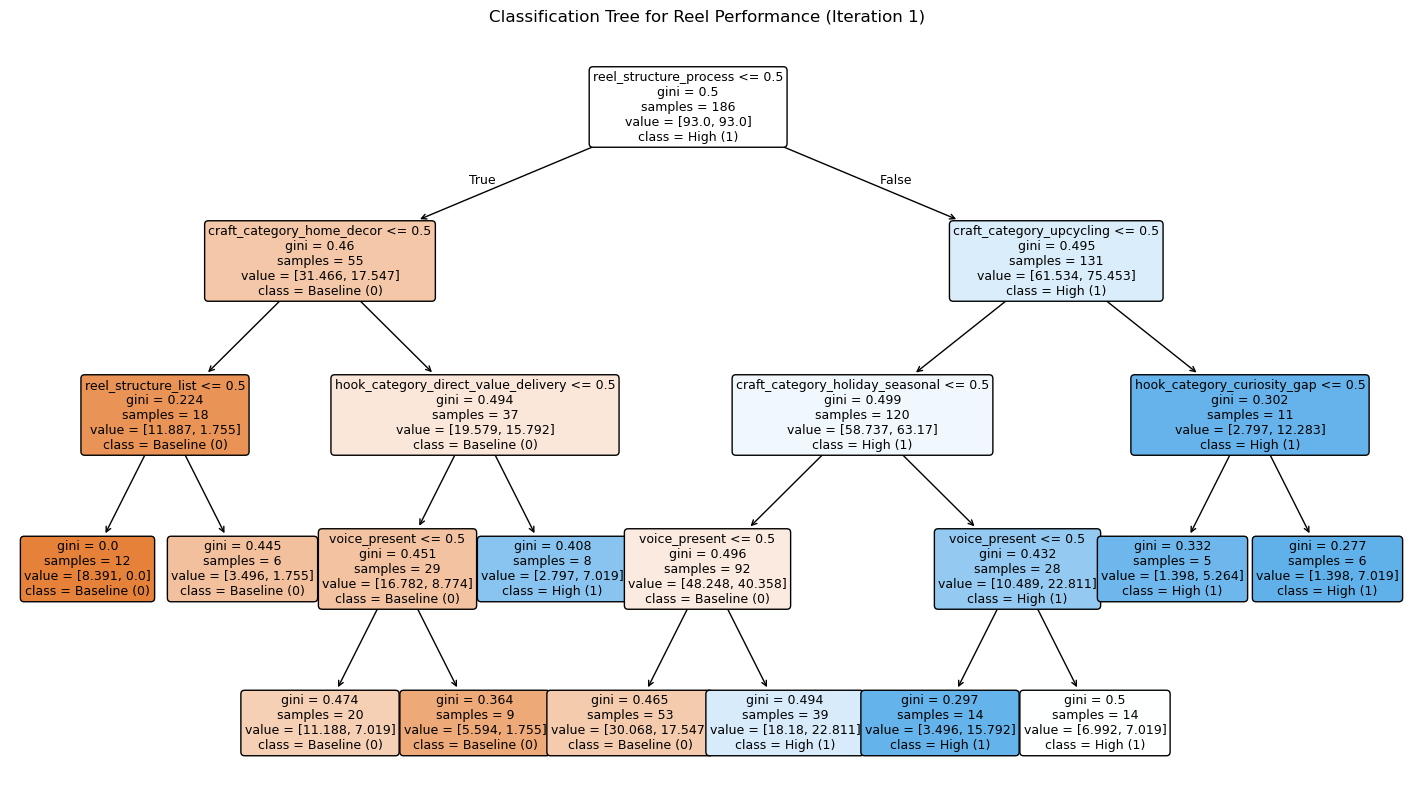

In [8]:
tree_1 = run_tree(split_1, 'Iteration 1')

---
### Iteration 2: content features plus interaction features

The same split, techniques, and tuning procedure are used, with the interaction features added to the predictors.

In [9]:
split_2 = make_split(base_features + interaction_features)

Training reels: 186 | Validation reels: 47 (13 high-performing)
Features used: 26 | Dropped as too rare (<10 reels): ['craft_category_costume_wearables', 'craft_category_fiber_arts', 'craft_category_fine_art_paint', 'craft_category_miniatures_dioramas', 'craft_category_sewing_fabric', 'reel_structure_narrative', 'hook_category_declarative_authority', 'hook_category_pain_point']


#### Logistic regression

In [10]:
logit_2 = run_logistic(split_2, 'Iteration 2')

Baseline logistic regression (l2, C=1):
              precision    recall  f1-score   support

           0       0.75      0.62      0.68        34
           1       0.32      0.46      0.38        13

    accuracy                           0.57        47
   macro avg       0.53      0.54      0.53        47
weighted avg       0.63      0.57      0.59        47

Tuning results (sorted by F1):
penalty    C  accuracy  precision  recall    f1
     l2 10.0     0.574      0.316   0.462 0.375
     l2  1.0     0.574      0.316   0.462 0.375
     l1 10.0     0.574      0.316   0.462 0.375
     l1  1.0     0.574      0.316   0.462 0.375
     l2  0.1     0.553      0.300   0.462 0.364
     l1  0.1     0.723      0.000   0.000 0.000

Final model: largest coefficients (positive = higher likelihood of high performance):
int_upcycling_process                   2.789
int_holiday_seasonal_process            2.739
int_home_decor_showcase                 2.011
int_curiosity_gap_process               1

#### k-nearest neighbors

In [11]:
knn_2 = run_knn(split_2, 'Iteration 2')

k-NN results (sorted by F1):
 k  accuracy  precision  recall    f1
 1     0.638      0.357   0.385 0.370
 5     0.745      0.600   0.231 0.333
 3     0.723      0.500   0.231 0.316
13     0.745      0.667   0.154 0.250
17     0.745      1.000   0.077 0.143
 7     0.702      0.333   0.077 0.125
15     0.702      0.333   0.077 0.125
11     0.681      0.250   0.077 0.118
 9     0.617      0.143   0.077 0.100
19     0.723      0.000   0.000 0.000

Best k by accuracy: 5 | best k by F1 (selected): 1
Accuracy favors large k because the model then mostly predicts the majority (baseline) class.
Caution: k=1 is the most flexible setting and copies the single closest reel, so with a validation set this small the choice of k is unstable.


#### Classification tree (exploratory)

Classification report:
              precision    recall  f1-score   support

           0       0.72      0.82      0.77        34
           1       0.25      0.15      0.19        13

    accuracy                           0.64        47
   macro avg       0.48      0.49      0.48        47
weighted avg       0.59      0.64      0.61        47

Feature importance (non-zero):
int_holiday_seasonal_process           0.3015
int_upcycling_process                  0.2614
hook_category_relatable_observation    0.1447
voice_present                          0.1320
craft_category_holiday_seasonal        0.1101
result_shown_first                     0.0491
int_curiosity_gap_process              0.0011


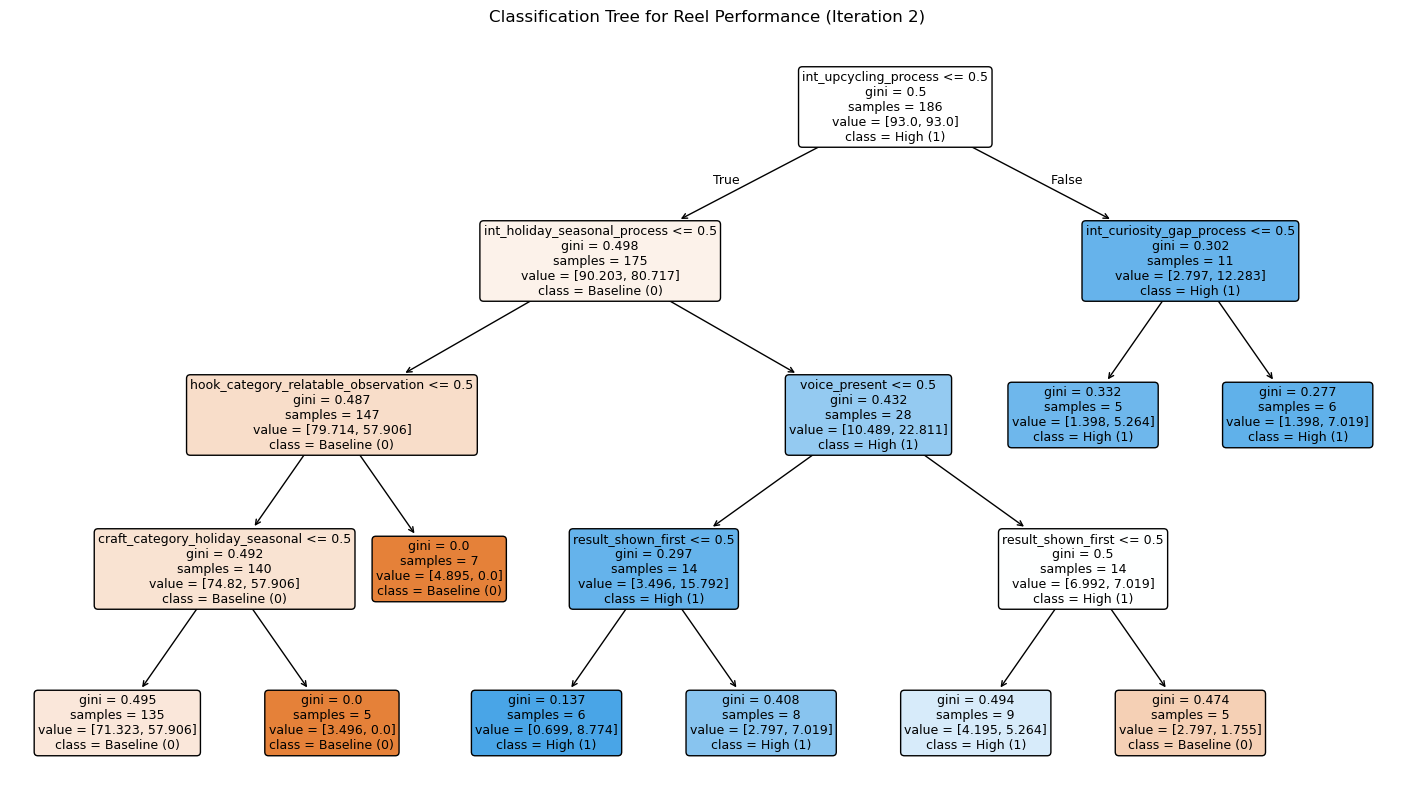

In [12]:
tree_2 = run_tree(split_2, 'Iteration 2')

## 4.4 Assess models

The table summarizes the final tuned model of each type in each iteration, on the validation set. Metrics are for the **high-performing class (1)**, except accuracy. Notebook 4 evaluates these results against the business goal.

In [13]:
results_df = pd.DataFrame(results)
display_cols = ['iteration', 'model', 'settings', 'accuracy', 'precision', 'recall', 'f1']
print(results_df[display_cols].round(3).to_string(index=False))

# Save for Notebook 4
results_df.to_csv('../Data/model_results.csv', index=False)

  iteration               model                        settings  accuracy  precision  recall    f1
Iteration 1 Logistic regression              penalty=l2, C=10.0     0.553      0.300   0.462 0.364
Iteration 1                k-NN                             k=1     0.638      0.357   0.385 0.370
Iteration 1 Classification tree max_depth=4, min_samples_leaf=5     0.574      0.267   0.308 0.286
Iteration 2 Logistic regression              penalty=l2, C=10.0     0.574      0.316   0.462 0.375
Iteration 2                k-NN                             k=1     0.638      0.357   0.385 0.370
Iteration 2 Classification tree max_depth=4, min_samples_leaf=5     0.638      0.250   0.154 0.190
